<a href="https://colab.research.google.com/github/edoardochiarotti/class_datascience/blob/main/2024/04_Probability/04_Probability_exercises.ipynb" target="_blank" rel="noopener"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probability: Exercises

In [9]:
# PACKAGES
%matplotlib inline
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import random as rd
import statistics as st
import pandas as pd

# SEABORN THEME
scale = 0.4
W = 16*scale
H = 9*scale
sns.set(rc = {'figure.figsize':(W,H)})
sns.set_style("white")

Main References:
- Resources' notebook [04_Probability.ipynb](https://github.com/edoardochiarotti/class_datascience/blob/main/2023/03_EDA-Visualization/Resources/03_EDA_Data-visualization.ipynb).
- A great source to learn probability and Statistics with Python [is this website](https://ethanweed.github.io/pythonbook/landingpage.html) by Weed and Navarro (translation of Navarro’s book [Learning Statistics with R](https://learningstatisticswithr.com/) in Python). For this Notebook, we borrow from Weed and Navarro's chapters on Statistical Theory. 
- For more theory in statistics and econometrics, we rely on
    - J. Wooldridge, Econometric Analysis of Cross Section and Panel Data, MIT Press, 2002
    - William H. Greene, Econometric Analysis, sixth edition, Pearson.

# Content
- [Probability: Exercises](#Probability:-Exercises)
    - [Exercise 1: Generate data](#Exercise-1:-Generate-data)
    - [Exercise 2: Density functions](#Exercise-2:-Density-functions)
    - [Exercise 3: The one-sample z-test (unknown mean and known variance)](#Exercise-3:-The-one-sample-z-test-(unknown-mean-and-known-variance))
    - [Exercise 4: The one-sample t-test (unknown mean and variance)](#Exercise-4:-The-one-sample-t-test-(unknown-mean-and-variance))

## Exercise 1: Generate data <a name="Exercise-1:-Generate-data"></a>
- As done in in the resources' notebook, generate 100 observations of CO2 emissions per capita. This variable distributes like a Normal with mean 5 tonnes and variance 4 tonnes.

In [19]:
# The seed : the number where the algorith needs to start for replicability

np.random.seed(seed=14396)

N = 100 

data = np.random.normal(loc=5, scale=2, size=N)
data

array([2.84810991, 6.03887459, 3.88828413, 4.01310188, 3.95942131,
       4.64577182, 4.87354647, 5.63017386, 2.31834735, 5.8015512 ,
       7.55731146, 4.38875052, 4.84765338, 5.37050662, 6.3493046 ,
       2.81093617, 2.89547666, 0.94961033, 8.38561754, 5.72400636,
       5.61407805, 4.32018833, 4.66236429, 3.33615127, 5.94229166,
       5.17642518, 3.02724363, 3.35426437, 4.23475603, 6.36834248,
       4.00460082, 5.38150176, 4.2365443 , 3.14874048, 7.90467632,
       5.1339192 , 8.00616796, 6.43738422, 6.03919122, 4.79770769,
       1.40813569, 4.02729357, 2.72389018, 4.01285659, 9.24825741,
       5.51082876, 6.80597851, 5.02663624, 7.57952003, 1.09456169,
       4.19858763, 4.60027782, 9.00425534, 5.9839116 , 6.42870706,
       6.05827731, 2.84090059, 5.37918627, 3.36162576, 2.56046749,
       2.56246182, 6.54473403, 2.39671803, 4.53441349, 5.99983365,
       4.67905504, 4.50098701, 5.24305689, 5.73742113, 3.17558927,
       5.55510084, 4.59649251, 5.71166491, 5.25186688, 5.50132

## Exercise 2: Density functions <a name="Exercise-2:-Density-functions"></a>

- Use a built-in function inside `stats.norm` to obtain the values of the density function (density values) for `draws_co2`, and comment what these values mean.

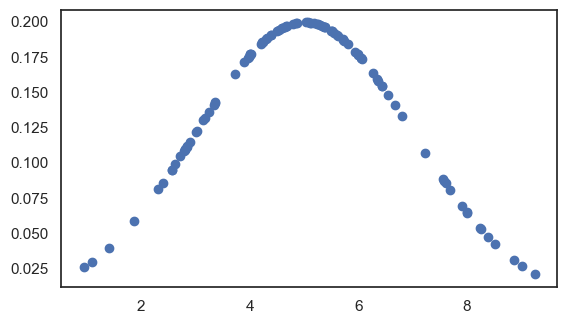

In [46]:
dens = stats.norm.pdf(data, loc=5, scale=2)
dens

x = np.linspace(stats.norm.ppf(0.01, 5, 2), stats.norm.ppf(0.99, 5,2), 100)

plt.scatter(data, dens)
plt.show()

Your answer here ...

- Use a built-in function inside `stats.norm` to obtain the values of the cumulative density function (cumulated probabilities) for `draws_co2`, and comment what these values mean.

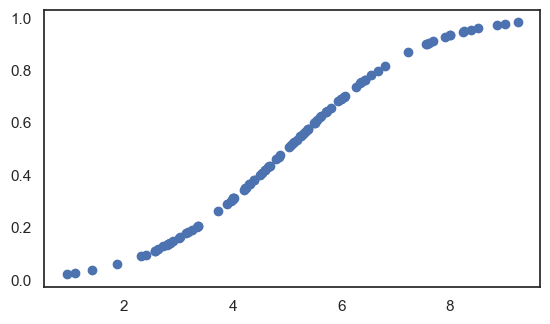

In [48]:
cdf = stats.norm.cdf(data, 5, 2)

plt.scatter(data, cdf)

Your answer here ...

- Use a built-in function inside `stats.norm` to obtain the 95th quantile (or percentile) of the distribution of CO2 emissions per capita (conceptually, it's the inverse of the one above) and explain what is the 95th quantile / percentile.

In [33]:
perc = stats.norm.ppf(0.95, 5, 2)
perc

np.float64(8.289707253902943)

Your answer here ...

- Use a combination of the generated array of CO2 emissions per capita, the Cumulative Density Function, and the Percentage Point Function to re-obtain the array of CO2 emissions per capita (tip: the PPF is the inverse of the CDF).

True

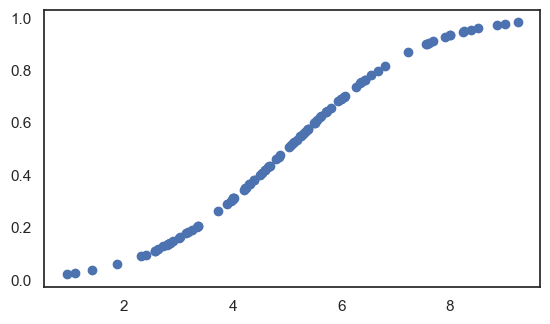

In [ ]:
probas = stats.norm.cdf(data, 5, 2)
probas

plt.scatter(data, probas)

data2 = stats.norm.ppf(probas, 5, 2)

np.allclose(data, data2)

## Exercise 3: The one-sample z-test (unknown mean and known variance) <a name="Exercise-3:-The-one-sample-z-test-(unknown-mean-and-known-variance)"></a>

- In the resources' notebook we have run a one-sample z-test on the mean with known standard deviation $\sigma=2$.
- Specifically, we tested if, based on our result, the population mean equals 5 tonnes per capita ($H_0$) or if it's different than 5 tonnes per capita ($H_1$). We were not able to reject the null hypothesis that the population mean equals 5 tonnes per capita.
- Here, use the code seen in the resources notebook to test if the population mean equals 0 tonnes per capita ($H_0$) or if it is different than 0 tonnes per capita.
- First, compute the z-statistic and comment on whether you accept or reject the null hypothesis based on the z-statistic.

In [55]:
beta_hat = st.mean(data)


sd_true = 2
beta_null = 0

z_stat = (beta_hat - beta_null) / (sd_true / np.sqrt(N))


We can see that $\lvert z \rvert$ > 1.96, then we can reject the null hypothesis based on the z-statistic test, at the 5% significance level

- Then, compute the p value and comment on whether you accept or reject the null hypothesis based on the p value.

In [59]:
lower_prob = st.NormalDist().cdf(-abs(z_stat))

p_value = 2 * lower_prob
p_value

0.0

We can see that p < 0.05 then we reject H0

- Then, as explained in the resources notebook, write down the equation of the 95% confidence interval under $H_0$ with $\beta_0=0$ tonnes per capita and known standard deviation $\sigma=2$ tonnes per capita.

Under the null hypothesis, **CI95** = 0 ± 0,39

- Finally, use python to compute this confidence interval and use it to either accept or reject the null hypothesis.

In [61]:
se = sd_true / np.sqrt(N)              # standard error = 0.2
z_crit = stats.norm.ppf(0.975)          # 1.96

ci_low  = beta_null - z_crit * se
ci_high = beta_null + z_crit * se

print(f"95% CI under H0: [{ci_low:.2f}, {ci_high:.2f}]")
print(f"beta_hat = {beta_hat:.2f}")

95% CI under H0: [-0.39, 0.39]
beta_hat = 5.01


Since beta_hat is not in the confidence interval, we can reject H0

## Exercise 4: The one-sample t-test (unknown mean and variance) <a name="Exercise-4:-The-one-sample-t-test-(unknown-mean-and-variance)"></a>

- If we do not know the variance, our test statistic will be as follows:
$$z_{\hat{\beta}} = \frac{\hat{\beta}-\beta_0}{\hat{\sigma}/\sqrt{N}}$$
<br><br>
- If this estimate has been constructed from $N$ observations, then the sampling distribution turns into a $t$-distribution with $N-1$ **_degrees of freedom_** (df). The $t$ distribution is very similar to the normal distribution, but has "heavier" tails.
- Similarly to what has been shown in class for the one-sample z test, run a t test with the null hypothesis $\beta = 5$. Specifically, compute the t statistic and comment on whether you accept or reject the null hypothesis.

In [79]:
beta_hat = st.mean(data)
sigma_hat = st.stdev(data)
beta_null = 5

t_stat = np.sqrt(N) * ((beta_hat - beta_null)/sigma_hat)

quant = stats.t.ppf(0.975, df=N-1)
t_stat, quant


(np.float64(0.03631614674452325), np.float64(1.9842169515086827))

Then since quant(0.05)= 1.98, we can't reject the null Hypothesis (abs(z))=0.01

- Use this test statistic to obtain the p value and comment on whether you accept or reject the null hypothesis based on the p value.

In [71]:
lower_prob_t = stats.t.cdf(-(np.abs(t_stat)), df=N-1)
p_value_t = 2* lower_prob_t
p_value_t

np.float64(0.9711034016535669)

We have p_value = 0.97>0.05 so we can't reject the null hypothesis. p_value = 0.97 means that if H0 is true, we have a 97% chance of observing a result at least as extreme as the one observed if we take another sample

- Use a built-in function in `scipy.stats` to check that you computed correctly t stat and p value.

In [76]:
res = stats.ttest_1samp(data, popmean=5)
res.pvalue

np.float64(0.9711034016535669)

- Now, use a built-in function inside `stats.t` to get the the critical values for the areas with cumulative probability $0.025$ and $0.975$ of your t-student distribution.

In [ ]:
cr_high = stats.t.ppf(0.975, df=N-1)
cr_low = stats.t.ppf(0.025, df=N-1)

se_hat = sigma_hat/10

cr_high, cr_low


(np.float64(1.9842169515086827), np.float64(-1.9842169515086832))

- Use these critical values and the estimate for the standard error to write down the equation of the 95% confidence interval under $H_0$ with $\beta_0=0$ tonnes per capita and unknown standard deviation.

Your anser here ...

- Compute this confidence interval via python and use it to either accept or reject the null hypothesis.

In [92]:
conf = (beta_null + cr_low * se_hat, beta_null + cr_high * se_hat)
print(conf)

bool(conf[0]<= beta_hat <= conf[1])

(np.float64(4.632266193694137), np.float64(5.367733806305863))


True

- Use a built-in function in `scipy.stats` to check that you computed correctly the confidence interval.

In [90]:
se_hat_t = stats.sem(data)
print(beta_null, stats.t.interval(0.95, df=N-1, loc=beta_null, scale=se_hat_t))

5 (np.float64(4.632266193694137), np.float64(5.367733806305863))
